In [ ]:
import pandas as pd

# Load Data

In [ ]:
# data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\tonghopdata.csv')

data = pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\GSE183635_TEP_Count_Matrix.csv')
# name_gene =  pd.read_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\183635\Human_CH38p13annot.csv', low_memory=False    )


In [ ]:
data

,Unnamed: 0,1-Vumc-HD-101-TR922,2-Vumc-HD-103-TR923,3-Vumc-HD-108-TR924,4-Vumc-HD-127-TR925,5-Vumc-HD-130-TR926,6-Vumc-HD-142-TR927,7-Vumc-HD-143-TR928,8-Vumc-HD-144-TR929,9-Vumc-HD-145-TR930,...,countMatrix.3502-NKI-4854-SARC-TR3080,countMatrix.3503-NKI-4707-SARC-TR3079,countMatrix.3504-NKI-4941-SARC-TR3084,countMatrix.3507-NKI-6348-SARC-TR3134,countMatrix.3508-NKI-5275-SARC-TR3099,countMatrix.3512-NKI-5148-SARC-TR3129,countMatrix.320-10,countMatrix.327-34,countMatrix.376-P-PH-001-013-TR1400,countMatrix.506-NKI-NSCLC-107-270
0,ENSG00000000419,5,79,58,128,93,12,0,0,18,...,3,0,1,2,9,16,22,21,0,1
1,ENSG00000000460,8,10,21,14,6,8,25,42,5,...,0,3,0,2,63,3,3,0,1,0
2,ENSG00000000938,24,336,334,59,120,22,31,13,19,...,8,45,1,7,163,90,46,75,14,8
3,ENSG00000001036,38,46,15,36,25,43,27,27,59,...,1,3,4,15,3,6,10,8,3,0
4,ENSG00000001461,72,17,11,9,18,28,5,6,49,...,1,1,0,0,12,2,6,6,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5435,ENSG00000271043,349,133,99,87,171,260,232,204,188,...,0,0,0,5,0,2,18,31,22,23
5436,ENSG00000272053,980,658,294,265,818,2066,1579,1161,2003,...,18,17,17,107,41,52,78,203,12,16
5437,ENSG00000272168,51,20,11,31,65,49,56,25,131,...,0,0,0,26,0,1,15,6,10,0
5438,ENSG00000272369,29,41,24,3,51,33,26,52,35,...,0,3,1,8,2,1,0,3,2,1


In [ ]:
import numpy as np

# Minimal TMM normalization adapted from edgeR logic
# Returns CPM and factors scaled so geometric mean of factors is 1.
def compute_tmm_cpm(counts_df, trim_M=0.3, trim_A=0.05, ref_sample=None):
    counts = counts_df.copy()
    lib_sizes = counts.sum(axis=0)

    # Pick reference sample: closest library size to median if none provided
    if ref_sample is None:
        ref_sample = (lib_sizes - lib_sizes.median()).abs().idxmin()
    ref_counts = counts[ref_sample]
    lib_ref = lib_sizes[ref_sample]

    factors = {}

    def tmm_factor(test_counts, lib_test):
        mask = (test_counts > 0) & (ref_counts > 0)
        if mask.sum() == 0:
            return 1.0

        test = test_counts[mask]
        ref = ref_counts[mask]

        logR = np.log2((test / lib_test) / (ref / lib_ref))
        logA = 0.5 * np.log2((test / lib_test) * (ref / lib_ref))
        weights = 1.0 / ((1.0 / test) + (1.0 / ref))

        # Trim extremes on M and A
        m_low, m_high = np.quantile(logR, [trim_M / 2, 1 - trim_M / 2])
        a_low, a_high = np.quantile(logA, [trim_A / 2, 1 - trim_A / 2])
        keep = (logR >= m_low) & (logR <= m_high) & (logA >= a_low) & (logA <= a_high)

        if keep.sum() == 0:
            return 1.0

        weighted_M = np.average(logR[keep], weights=weights[keep])
        return 2 ** weighted_M

    for col in counts.columns:
        factors[col] = tmm_factor(counts[col], lib_sizes[col])

    factors = pd.Series(factors)
    factors = factors / np.exp(np.log(factors).mean())  # rescale to geometric mean 1
    effective_lib_sizes = lib_sizes * factors

    cpm = counts.divide(effective_lib_sizes, axis=1) * 1_000_000
    return cpm, factors, effective_lib_sizes

In [ ]:
# Apply TMM normalization → CPM → log2(CPM+1)
count_cols = data.columns.drop('Unnamed: 0')
counts_numeric = data[count_cols].apply(pd.to_numeric, errors='coerce').fillna(0)

# TMM factors trimmed at 30% for M and 5% for A (edgeR defaults)
tmm_cpm, tmm_factors, tmm_libsizes = compute_tmm_cpm(
    counts_numeric,
    trim_M=0.3,
    trim_A=0.05,
)

tmm_log2 = np.log2(tmm_cpm + 1)

# Reattach gene column and use the normalized values for downstream steps
tmm_log2.insert(0, 'Unnamed: 0', data['Unnamed: 0'])
raw_counts = data.copy()
data = tmm_log2

tmm_log2.head()

In [ ]:
data

In [ ]:
data.drop_duplicates(inplace=True)

In [ ]:
# Transpose so samples become rows
data_transposed = data.set_index('Unnamed: 0').T
data_transposed

In [ ]:
# data_transposed.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\otherdata can be merged\raw.csv', index=True )

In [ ]:
data_transposed['cancer_type'] = (
    data_transposed['cancer_type']
    .replace('Other/Unknown', 'Asymptomatic_Controls')
)


In [ ]:
data_transposed['cancer_type'].value_counts()

In [ ]:
# Extract the names of the remaining 338
remaining_unknowns = [c for c in data.columns if categorize_tumor_type(c) == 'Other/Unknown']

# Look for patterns

print(pd.Series(remaining_unknowns).head(44))

In [ ]:
data_transposed = data_transposed[
    data_transposed['cancer_type'] != 'Symptomatic_Control'
]

In [ ]:
data_transposed.reset_index(drop=True, inplace=True)


In [ ]:
data_transposed

In [ ]:
# 4) Filter low-expression genes (expressed in ≥10% of samples)
min_samples = len(data_transposed) * 0.01
gene_cols = data_transposed.columns.drop('cancer_type')
expressed_genes_mask = (data_transposed[gene_cols] > 0).sum(axis=0) >= min_samples
data_filtered = data_transposed.loc[:, expressed_genes_mask.index[expressed_genes_mask]]
data_filtered['cancer_type'] = data_transposed['cancer_type']


In [ ]:

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier


In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
data_normalized = data_filtered.copy()

In [ ]:
# # # 5) MinMax normalize gene expression values
# # data_normalized = data_filtered.copy()

# # Get gene columns (exclude cancer_type)
# gene_cols = data_normalized.columns.drop('cancer_type')

# # Initialize MinMaxScaler
# scaler = MinMaxScaler()

# # Fit and transform only the gene expression columns
# data_normalized[gene_cols] = scaler.fit_transform(data_filtered[gene_cols])

# # Keep cancer_type column
# data_normalized['cancer_type'] = data_filtered['cancer_type']


In [ ]:
data_normalized

In [ ]:
# 6) Split features/labels
X = data_normalized.drop(columns=['cancer_type'])
y = data_normalized['cancer_type']


In [ ]:
X

In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\y_multi_ori.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Multi\data\normalized_X_multi_log.csv', index=False)

In [ ]:
# X.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv', index=False)

In [ ]:
y = y.apply(lambda x: 1 if x != 'Asymptomatic_Controls' and x != 'Symptomatic_Control' else 0)

In [ ]:
y.value_counts()

In [ ]:
# y.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv', index=False)

# embedded RF with stratify k fold

In [ ]:
import pandas as pd
import numpy as np
import json
import warnings
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Set random state for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
# X = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\X_normalized_binary_log.csv", low_memory=False)
# y = pd.read_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\y_normalized_binary.csv", low_memory=False).values.ravel()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)

In [ ]:
# X_train.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_train.csv", index= False)
# X_test.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_test.csv", index= False)
# y_train.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\y_train.csv", index= False)
# y_test.to_csv(r"D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\y_test.csv", index= False)


In [ ]:

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)
gene_names = X_train.columns.values

In [ ]:
print("  This may take a few minutes...")

# Parameter grid for RandomForest
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5]
}

# RandomForest classifier
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight='balanced',
    n_jobs=-1
)

# Stratified K-Fold
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Grid search
grid_search_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=cv_inner,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=0
)

grid_search_rf.fit(X_scaled, y_train)

# Get feature importances
best_rf = grid_search_rf.best_estimator_
feature_importances = best_rf.feature_importances_

### Ranking all genes by RandomForest importance...

In [ ]:
# Create dataframe with ALL genes and their importance scores
rf_df = pd.DataFrame({
    'gene': gene_names,
    'importance': feature_importances
})
rf_df = rf_df.sort_values('importance', ascending=False)

In [ ]:
rf_df

In [ ]:
rf_df.to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\feature_importance.csv', index=False)

In [ ]:
all_features = (
    rf_df.sort_values('importance', ascending=False)
    .head(5440)['gene']
    .tolist()
)

In [ ]:
X_train[all_features]

In [ ]:
X_test[all_features]

In [ ]:
X_train[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_train.csv', index=False)
X_test[all_features].to_csv(r'D:\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python\Binary\data\data ranked sk rf\X_test.csv', index=False)

In [ ]:
# import matplotlib.pyplot as plt
# plt.figure(figsize=(6, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'], color='blue')
# plt.xlabel('Importance Score')
# plt.ylabel('Feature')
# plt.title('Feature Importance Scores from Random Forest')
# plt.gca().invert_yaxis()  # To display the highest importance at the top
# plt.show()

# Start ML


In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [ ]:
X_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\X_train_rF_DEG_train_lung.csv",low_memory = False)
X_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\X_test_rF_DEG_train_lung.csv",low_memory = False)

y_train = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\y_train_rF_DEG_train.csv",low_memory = False)
y_test = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\ranked rf\y_test_rF_DEG_train.csv",low_memory = False)

In [ ]:
X_test

,ENSG00000227165,ENSG00000111196,ENSG00000240225,ENSG00000142089,ENSG00000130948,ENSG00000103512,ENSG00000142856,ENSG00000249307,ENSG00000163359,ENSG00000260661,...,ENSG00000186166,ENSG00000007392,ENSG00000197635,ENSG00000012223,ENSG00000137509,ENSG00000115590,ENSG00000052749,ENSG00000161944,ENSG00000129824,ENSG00000173535
0,6.451547,5.348242,5.063048,7.340270,4.175718,5.665411,8.002006,4.625584,5.027229,3.306779,...,4.346157,4.521600,3.711639,2.830723,4.138130,2.830723,2.830723,2.830723,5.742559,2.830723
1,6.630307,5.769564,5.769564,3.921878,4.450995,5.844078,6.824695,4.551511,5.373541,3.728479,...,4.886915,5.026358,3.470567,7.424813,5.026358,3.921878,6.730802,4.644246,2.830723,3.921878
2,4.806340,4.468396,2.830723,7.664287,3.783802,4.345067,4.579964,3.783802,6.068926,2.830723,...,6.057216,6.159271,2.830723,2.830723,4.972535,3.988061,3.783802,6.068926,7.984931,4.579964
3,6.948542,6.390590,5.743158,5.220952,3.531932,6.448757,7.818158,4.996651,4.023021,4.564307,...,3.751771,3.531932,2.830723,4.535230,2.830723,3.328968,4.023021,2.830723,2.830723,3.924027
4,7.263197,6.852681,6.983045,5.905861,4.972501,6.667009,7.623942,4.838434,3.564025,4.543893,...,2.830723,3.401148,2.830723,2.830723,4.221185,3.161482,2.830723,3.401148,5.322133,3.161482
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178,7.793642,7.068577,6.270715,4.704627,5.540731,6.599390,9.150536,4.909011,5.282180,4.881746,...,2.830723,2.830723,2.830723,2.830723,3.223397,2.830723,2.830723,3.223397,3.223397,2.830723
179,6.029134,4.743265,5.561667,4.795813,3.522366,4.875604,7.151842,3.920887,5.369384,3.897971,...,2.830723,3.441971,2.830723,2.830723,3.063233,2.830723,2.830723,2.830723,2.830723,2.830723
180,6.585824,4.597360,5.647809,6.105820,4.280496,6.059986,8.286562,4.396034,6.193255,4.339747,...,4.848015,5.493568,2.830723,2.830723,2.830723,2.830723,4.449686,3.610574,6.044371,4.217875
181,4.978482,4.240479,4.631622,7.745341,2.830723,4.926833,6.610647,3.773898,5.122217,3.605274,...,3.913699,2.830723,2.830723,2.830723,3.913699,2.830723,2.830723,2.830723,5.166854,3.381660


In [ ]:
# X_train = X_train.iloc[:,:300]
# 0.00055

In [ ]:
# X_test = X_test.iloc[:,:300]

In [ ]:
X_train = X_train.iloc[:,:410]
X_test = X_test.iloc[:,:410]
# cut at >= 0.00080 point

In [ ]:
from sklearn.model_selection import StratifiedKFold

In [ ]:
from xgboost import XGBClassifier

In [ ]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
x_train_sc = scale.fit_transform(X_train)
x_test_sc = scale.transform(X_test)

In [ ]:
list_feature = list(X_train.columns)

In [ ]:
ranks = []
for i in range(len(list_feature)):
    arr = []
    for j in range(i+1):
        arr.append(list_feature[j])
    ranks.append(arr)

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC

pipe = Pipeline([
    ("smote", SMOTE(k_neighbors=3, random_state=42)),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",  
        probability=True,
        random_state = 42
    ))
])

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
from sklearn.metrics import confusion_matrix,roc_auc_score
def cfm(y_test,y_pred,y_prob):
    auc = roc_auc_score(y_test,y_prob)
    tn,fp,fn,tp = confusion_matrix(y_test,y_pred).ravel()
    acc = accuracy_score(y_test,y_pred)
    recall = tp/(tp+fn)
    precision = tp/(tp+fp)
    specificity = tn/(tn+fp)
    sensitivity = tp / (tp+fn)
    f1_score = round((2*recall*precision)/(recall+precision),3)
    return np.array([acc,recall,precision,specificity,sensitivity,f1_score,auc])

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from skopt import BayesSearchCV
from skopt.space import Real, Categorical, Integer # Skopt uses specialized spaces
from sklearn.metrics import accuracy_score
import numpy as np

# Grid search

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

model = SVC(random_state=11,probability=True)
params = {
    
    
    "C": [0.01, 0.1, 1, 10],
    "kernel": ['linear', 'poly', 'rbf'],
    "gamma": ['scale', 'auto', 1e-4, 0.01],
    'degree': [2,3], 
    'coef0': [ 0.1, 0.5],
    # 'random_state': [122],
    # 'probability': [True]
}

acc_max_rank = None
acc_max = -np.inf
result = []
result2 = []
best_paramet = None

from sklearn.metrics import make_scorer, recall_score, confusion_matrix

# Custom Specificity Scorer: TN / (TN + FP)
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    # This assumes binary classification; adjust if multiclass
    tn, fp, fn, tp = cm.ravel()
    return tn / (tn + fp)

scoring_metrics = {
    'ACC': 'accuracy',
    'Recall': 'recall',
    'Precision': 'precision',
    'Sp': make_scorer(specificity_score),
    'Sn': 'recall', # Sn (Sensitivity) is the same as Recall
    'f1_Score': 'f1',
    'AUC': 'roc_auc'
}

grid_search = GridSearchCV(
    estimator=model, 
    param_grid=params, 
    cv=5, 
    scoring=scoring_metrics, 
    refit='ACC', # The "best" model will be chosen based on Accuracy
    return_train_score=False, 
    n_jobs=-1,
    verbose = 2
)

result = []

for i, rank in enumerate(ranks[10:], start=10):

    # Fit using cross-validation on the first i+1 features
    grid_search.fit(x_train_sc[:, :i+1], y_train['cancer_type'])
    
    best_idx = grid_search.best_index_
    cv_res = grid_search.cv_results_
    
    # Helper to format percentages
    def fmt(metric):
        return f"{cv_res[f'mean_test_{metric}'][best_idx] * 100:.2f}%"

    # Match your df_result columns: 
    # ['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter']
    result.append([
        rank,
        fmt('ACC'),
        fmt('Recall'),
        fmt('Precision'),
        fmt('Sp'),
        fmt('Sn'),
        fmt('f1_Score'),
        fmt('AUC'),
        grid_search.best_params_
    ])

    

    

    df_result = pd.DataFrame(result)
    df_result.columns = ['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter']  
    df_result.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\SVM_DEG_on_training_24_4.csv", index=False)

    best_parameters = grid_search.best_params_
    y_pred = grid_search.predict(x_test_sc[:, :i+1])
    y_prob = grid_search.predict_proba(x_test_sc[:, :i+1])[:, 1]
    acc = accuracy_score(y_test,y_pred)
    evaluate = cfm(y_test,y_pred,y_prob)
    result2.append([rank,'%.2f'%(evaluate[0]*100)+'%','%.2f'%(evaluate[1]*100)+'%','%.2f'%(evaluate[2]*100)+'%','%.2f'%(evaluate[3]*100)+'%','%.2f'%(evaluate[4]*100)+'%','%.2f'%(evaluate[5]*100)+'%','%.2f'%(evaluate[6]*100)+'%',best_parameters])

    df_result2 = pd.DataFrame(result2)
    df_result2.columns = ['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter']
    df_result2.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2_lung\Binary\data\sfs\SVM_DEG_on_training(test_selected)_24_4.csv", index=False)


Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 192 candidates, totalling 9

In [ ]:
# df_result = pd.DataFrame(result)
# df_result.columns = ['Gene','ACC','Recall','Precision','Sp','Sn','f1_Score','AUC','Parameter']
df_result

,Gene,ACC,Recall,Precision,Sp,Sn,f1_Score,AUC,Parameter
0,"[ENSG00000227165, ENSG00000111196, ENSG0000024...",84.38%,85.13%,87.26%,83.37%,85.13%,86.18%,89.83%,"{'C': 0.01, 'coef0': 0.1, 'degree': 2, 'gamma'..."
1,"[ENSG00000227165, ENSG00000111196, ENSG0000024...",83.56%,84.41%,86.59%,82.41%,84.41%,85.46%,89.60%,"{'C': 0.1, 'coef0': 0.5, 'degree': 2, 'gamma':..."
2,"[ENSG00000227165, ENSG00000111196, ENSG0000024...",83.56%,84.89%,86.17%,81.77%,84.89%,85.52%,90.13%,"{'C': 1, 'coef0': 0.5, 'degree': 2, 'gamma': 0..."
3,"[ENSG00000227165, ENSG00000111196, ENSG0000024...",83.29%,84.89%,85.73%,81.15%,84.89%,85.30%,89.95%,"{'C': 0.1, 'coef0': 0.1, 'degree': 2, 'gamma':..."
4,"[ENSG00000227165, ENSG00000111196, ENSG0000024...",85.07%,85.61%,87.92%,84.34%,85.61%,86.73%,92.37%,"{'C': 1, 'coef0': 0.1, 'degree': 2, 'gamma': '..."
...,...,...,...,...,...,...,...,...,...
196,"[ENSG00000227165, ENSG00000111196, ENSG0000024...",90.96%,89.68%,94.22%,92.65%,89.68%,91.86%,96.89%,"{'C': 1, 'coef0': 0.5, 'degree': 3, 'gamma': '..."
197,"[ENSG00000227165, ENSG00000111196, ENSG0000024...",90.82%,93.04%,91.13%,87.85%,93.04%,92.05%,96.66%,"{'C': 10, 'coef0': 0.1, 'degree': 2, 'gamma': ..."
198,"[ENSG00000227165, ENSG00000111196, ENSG0000024...",90.68%,89.44%,93.95%,92.33%,89.44%,91.61%,96.88%,"{'C': 1, 'coef0': 0.5, 'degree': 3, 'gamma': '..."
199,"[ENSG00000227165, ENSG00000111196, ENSG0000024...",90.82%,89.92%,93.78%,92.01%,89.92%,91.76%,96.91%,"{'C': 10, 'coef0': 0.5, 'degree': 3, 'gamma': ..."


In [ ]:
# df_result.to_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\SVM_DEG_training.csv", index=False)

In [ ]:
xxx

NameError: name 'xxx' is not defined

# Feature select sfs

In [ ]:
df_result = pd.read_csv(r"C:\Users\chaulh\Downloads\Trang_tre_trau\paper\minh\paper 2026\Gene Expression Omnibus (GEO) Dataset GSE68086\python_desque2\Binary\data\sfs\SVM_DEG_training.csv", low_memory=False)

In [ ]:
# percent_cols = ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]

# for col in percent_cols:
#     df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [ ]:
# for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
#     df_result[col] = df_result[col].str.rstrip("%").astype(float)

In [ ]:
# for col in ["ACC", "Recall", "Precision", "Sp", "Sn", "f1_Score", "AUC"]:
#     df_result2[col] = df_result2[col].str.rstrip("%").astype(float)

In [ ]:
# 1. Apply the Standard Definition of Balanced Accuracy
df_result['BA'] = (df_result['Sn'] + df_result['Sp']) / 2

In [ ]:
# 1. Apply the Standard Definition of Balanced Accuracy
df_result2['BA'] = (df_result2['Sn'] + df_result['Sp']) / 2

In [ ]:
# Use '&' to ensure BOTH conditions are met
sp_threshold = 0
auc_threshold = 80.0

# This creates a strict filter
mask = (df_result["Sp"] >= sp_threshold) & (df_result["AUC"] >= auc_threshold)
filtered_df = df_result[mask]

if not filtered_df.empty:
    best_row = filtered_df.loc[filtered_df["BA"].idxmax()]
    print("Best Model Meeting Strict Criteria:")
    print(best_row)
else:
    print(f"No models found with Sp > {sp_threshold} and AUC > {auc_threshold}.")
    # Optional: see what the highest Sp available is
    print(f"Max Sp in data: {df_result['Sp'].max()}")

Best Model Meeting Strict Criteria:
Gene         [ENSG00000111196, ENSG00000227165, ENSG0000024...
ACC                                                      90.34
Recall                                                   95.32
Precision                                                92.91
Sp                                                       69.63
Sn                                                       95.32
f1_Score                                                 94.09
AUC                                                      93.32
Parameter    {'C': 10, 'coef0': 0.1, 'degree': 2, 'gamma': ...
BA                                                      82.475
Name: 183, dtype: object


In [ ]:
df_result.loc[df_result["Precision"].idxmax()]

Gene         [ENSG00000227165, ENSG00000111196, ENSG0000024...
ACC                                                      92.05
Recall                                                   90.41
Precision                                                95.48
Sp                                                       94.25
Sn                                                       90.41
f1_Score                                                 92.86
AUC                                                      96.26
Parameter    {'C': 1, 'coef0': 0.1, 'degree': 2, 'gamma': 0...
BA                                                       92.33
Name: 34, dtype: object

In [ ]:
df_result2.loc[34]

Gene         [ENSG00000227165, ENSG00000111196, ENSG0000024...
ACC                                                      89.07
Recall                                                   85.71
Precision                                                94.74
Sp                                                       93.59
Sn                                                       85.71
f1_Score                                                  90.0
AUC                                                      95.23
Parameter    {'C': 1, 'coef0': 0.1, 'degree': 2, 'gamma': 0...
BA                                                       89.98
Name: 34, dtype: object

In [ ]:
df_result2.loc[df_result2["ACC"].idxmax()]

Gene         [ENSG00000227165, ENSG00000111196, ENSG0000024...
ACC                                                     91.26%
Recall                                                  87.62%
Precision                                               96.84%
Sp                                                      96.15%
Sn                                                      87.62%
f1_Score                                                92.00%
AUC                                                     96.11%
Parameter    {'C': 1, 'coef0': 0.1, 'degree': 2, 'gamma': '...
Name: 16, dtype: object

In [ ]:
best_genes = df_result.loc[df_result["ACC"].idxmax(), "Gene"]

In [ ]:
# import ast

# # Convert string → list
# best_genes = ast.literal_eval(best_genes)

In [ ]:
# Select features
X_train = X_train[best_genes]
X_test  = X_test[best_genes]

In [ ]:
X_train

,ENSG00000240225,ENSG00000111196,ENSG00000227165,ENSG00000005961,ENSG00000142089,ENSG00000103512,ENSG00000130948,ENSG00000213465,ENSG00000103316,ENSG00000142856,...,ENSG00000105369,ENSG00000156304,ENSG00000128731,ENSG00000241973,ENSG00000178950,ENSG00000135899,ENSG00000173575,ENSG00000124383,ENSG00000007202,ENSG00000164808
0,5.029751,5.313933,6.830194,12.739048,5.163708,5.847213,3.421733,4.456664,6.060632,6.396570,...,2.977562,2.977562,4.880156,4.880156,6.010254,3.421733,6.667921,2.977562,5.064561,2.977562
1,4.937442,4.567253,5.657219,12.818652,6.938392,5.554333,2.977562,4.826059,5.273281,7.267184,...,2.977562,2.977562,4.567253,5.527353,4.894071,3.906867,6.391238,2.977562,4.595823,3.716893
2,6.350295,6.504281,7.332512,12.668418,5.189230,7.662607,4.741644,4.782346,5.001946,8.019397,...,4.009663,4.161411,4.967904,5.930801,5.098964,5.001946,6.435281,3.826072,4.292595,4.088622
3,7.587544,7.099868,7.701091,12.174109,6.064303,7.014400,5.640744,4.189897,5.880896,6.875797,...,3.690989,2.977562,4.709205,5.831012,5.155216,4.927056,6.595267,4.364921,4.189897,2.977562
4,2.977562,2.977562,6.625362,12.355583,6.279014,5.397404,4.777392,5.124102,5.989692,6.404094,...,4.288787,4.288787,5.397404,4.288787,5.989692,7.566784,8.893093,5.397404,5.397404,5.624376
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1610,6.827255,6.566049,7.278084,13.250418,4.750060,6.910702,4.727932,4.267806,3.952941,8.081787,...,4.083676,4.332976,4.951880,7.161996,5.644966,5.092907,6.408566,3.853177,4.771792,4.423809
1611,5.055621,5.438894,5.789434,11.495049,6.730757,7.121808,4.181500,5.298584,2.977562,7.998309,...,5.055621,4.963363,5.981778,5.936123,5.370572,8.508766,8.062493,6.649091,5.736876,5.503925
1612,5.383968,5.934437,7.212175,12.435184,4.671672,7.225306,5.211901,4.348262,4.044359,7.638879,...,4.854550,4.521444,5.136278,6.414964,5.856632,5.035127,7.044439,3.991813,4.553085,4.854550
1613,2.977562,2.977562,6.291087,12.095441,6.916693,5.526078,2.977562,4.566351,5.526078,5.830206,...,2.977562,2.977562,5.830206,5.133454,4.566351,7.755323,8.549032,6.079483,2.977562,2.977562


# Test set

In [ ]:
X_train = X_train.iloc[:,:183]

X_test = X_test.iloc[:,:183]

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
X_test

,ENSG00000111196,ENSG00000227165,ENSG00000240225,ENSG00000005961,ENSG00000142089,ENSG00000103512,ENSG00000142856,ENSG00000130948,ENSG00000133742,ENSG00000102265,...,ENSG00000104805,ENSG00000198791,ENSG00000239839,ENSG00000154359,ENSG00000149243,ENSG00000108509,ENSG00000136842,ENSG00000206503,ENSG00000197386,ENSG00000240497
0,6.151981,6.557882,6.369384,12.457289,4.905674,5.348968,7.626873,4.215410,5.217000,9.304288,...,6.626812,4.492682,3.431737,5.922836,2.862767,6.503906,2.862767,8.895796,6.054710,6.104184
1,6.287276,7.532851,6.596894,12.636924,5.120737,6.283294,7.029614,5.235881,5.102101,9.734786,...,6.736926,4.340461,5.842251,4.994591,4.772760,4.517776,4.016803,9.049851,5.921754,6.271281
2,4.604866,7.222442,5.075046,12.204291,5.855117,5.258570,7.647148,3.956545,2.862767,10.257892,...,6.586779,4.206240,2.862767,4.963008,4.524354,6.017013,3.443818,8.862064,6.568610,5.660412
3,6.616302,7.431529,6.519848,12.012345,5.488874,7.389859,8.062581,4.347607,3.934829,9.533788,...,6.019996,4.091849,3.308796,5.971844,2.862767,4.922387,4.403141,8.543922,5.834721,6.330366
4,5.601909,6.368035,4.518871,11.231793,5.776021,6.614165,8.495482,5.554726,4.715469,9.701591,...,6.471646,4.282562,4.621159,6.918417,5.034648,4.803093,3.979377,10.543148,5.601909,6.394654
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,5.407814,6.281957,4.622012,13.744251,5.946011,5.877408,6.400027,3.588673,3.993505,9.285007,...,6.933797,4.095529,2.862767,5.676055,5.374486,6.478733,2.862767,10.175079,6.400027,5.853773
400,5.890345,7.119356,6.005102,11.715049,6.182369,7.041712,8.925573,4.856984,4.047641,10.149220,...,6.646028,4.856984,3.176751,5.416550,5.121875,4.700648,4.250359,9.972234,5.329594,6.568838
401,5.472975,5.545089,5.396845,12.794101,5.741221,4.933786,6.744553,4.384664,4.933786,9.196762,...,7.041371,4.689782,4.194905,4.547014,4.689782,5.741221,4.547014,7.549237,5.396845,5.741221
402,7.243511,7.456343,6.570820,12.211756,6.356341,6.228165,4.876281,4.350020,3.784120,9.791703,...,6.286567,4.194355,2.862767,4.329094,5.434533,5.039472,4.011339,9.193629,5.576198,6.187848


In [ ]:
from sklearn.preprocessing import StandardScaler
scale = StandardScaler()
X_train = scale.fit_transform(X_train)
X_test = scale.transform(X_test)

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC

pipe = Pipeline([
    ("smote", SMOTE(k_neighbors=3, random_state=42)),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",  
        probability=True,
        random_state = 42
    ))
])
svm_model = SVC(
    random_state=11,probability=True
)

In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
from sklearn.model_selection import GridSearchCV


param_grid = {
    # "C": [0.1, 1, 10, 100, 1000],
    # "kernel": ["linear", "rbf"],
    # "gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1],
    # 'C': [1], 
    # 'coef0': [0.5], 
    # 'degree': [2], 
    # 'gamma': [], 
    # 'kernel': ['poly']
    

    'C': [10], 
    'coef0': [0.1], 
    'degree': [2], 
    'gamma': ['scale'], 
    'kernel': ['rbf']
    
    # 'C': 10, 'coef0': 0.1, 'degree': 2, 'gamma': 'scale', 'kernel': 'rbf'

    # 'C': 1, 'coef0': 0.5, 'degree': 3, 'gamma': 0.01, 'kernel': 'poly'
# 'C': [10], 'kernel': ['rbf'], 'gamma': ['auto'], 'degree': [3], 'coef0': [0.1]
    # 'C': 10, 'coef0': 0.5, 'degree': 2, 'gamma': 0.01, 'kernel': 'poly'

# "{'C': 10, 'coef0': 0.1, 'degree': 2, 'gamma': 0.01, 'kernel': 'rbf'}"
    # {'C': 1, 'coef0': 0.5, 'degree': 2, 'gamma': 'scale', 'kernel': 'poly'
    # "C": [10],
    # "kernel": ["rbf"],
    # "gamma": ["scale", "auto", 0.01],
}

grid_search = GridSearchCV(
    estimator= svm_model,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    verbose=1,
 )


In [ ]:
import time
start_time = time.time()
grid_search.fit(X_train, y_train['cancer_type'])
end_time = time.time()

Fitting 5 folds for each of 1 candidates, totalling 5 fits


In [ ]:
import pandas as pd
import numpy as np

# Lấy kết quả từ GridSearch
results = grid_search.cv_results_

# Tạo DataFrame
df_results = pd.DataFrame(results)

# Tính phương sai từ std (vì sklearn cung cấp std)
df_results['var_test_score'] = df_results['std_test_score'] ** 2

# Chọn các cột quan trọng
summary_table = df_results[[
    'params',
    'mean_test_score',
    'std_test_score',
    'var_test_score',
    'rank_test_score'
]]

# Sắp xếp theo mean_test_score giảm dần
summary_table = summary_table.sort_values(by='mean_test_score', ascending=False)


In [ ]:
summary_table.head(10)    

,params,mean_test_score,std_test_score,var_test_score,rank_test_score
0,"{'C': 10, 'coef0': 0.1, 'degree': 2, 'gamma': ...",0.891641,0.017182,0.000295,1


In [ ]:
best_params = grid_search.best_params_

In [ ]:
best_accuracy = grid_search.best_score_

In [ ]:
best_params

{'C': 10, 'coef0': 0.1, 'degree': 2, 'gamma': 'scale', 'kernel': 'rbf'}

In [ ]:
best_accuracy

np.float64(0.891640866873065)

In [ ]:
# Calculate training time
training_time = end_time - start_time

In [ ]:
y_pred = grid_search.predict(X_test)

In [ ]:
from sklearn.metrics import classification_report

### Reslut for testing set

In [ ]:
from sklearn.metrics import roc_curve, auc

In [ ]:
print("Training time:", training_time, "seconds")
print(classification_report( y_test['cancer_type'],y_pred,digits=6))


Training time: 35.519468545913696 seconds
              precision    recall  f1-score   support

           0   0.708861  0.717949  0.713376        78
           1   0.932308  0.929448  0.930876       326

    accuracy                       0.888614       404
   macro avg   0.820584  0.823698  0.822126       404
weighted avg   0.889167  0.888614  0.888883       404



### Plot Figure

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sn

Text(113.9222222222222, 0.5, 'Predicted Values')

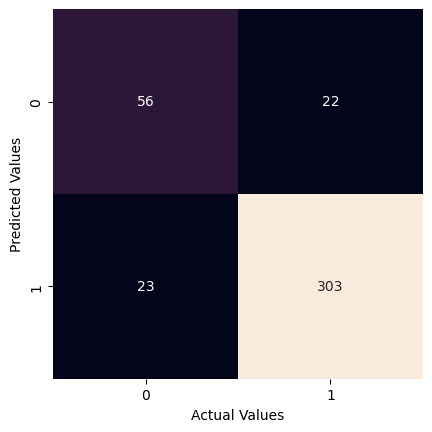

In [ ]:
mat_imp = confusion_matrix(y_test['cancer_type'],y_pred)
sn.heatmap(mat_imp,square=True, annot=True, fmt='d', cbar=False)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

In [ ]:
from sklearn.metrics import roc_curve, auc
y_scores = grid_search.predict_proba(X_test)
fpr, tpr, thresholds = roc_curve(y_test['cancer_type'], y_scores[:, 1])
roc_auc = auc(fpr, tpr)
roc_auc

0.9447852760736196

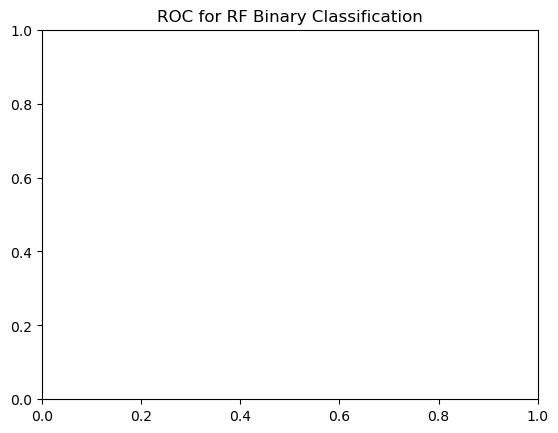

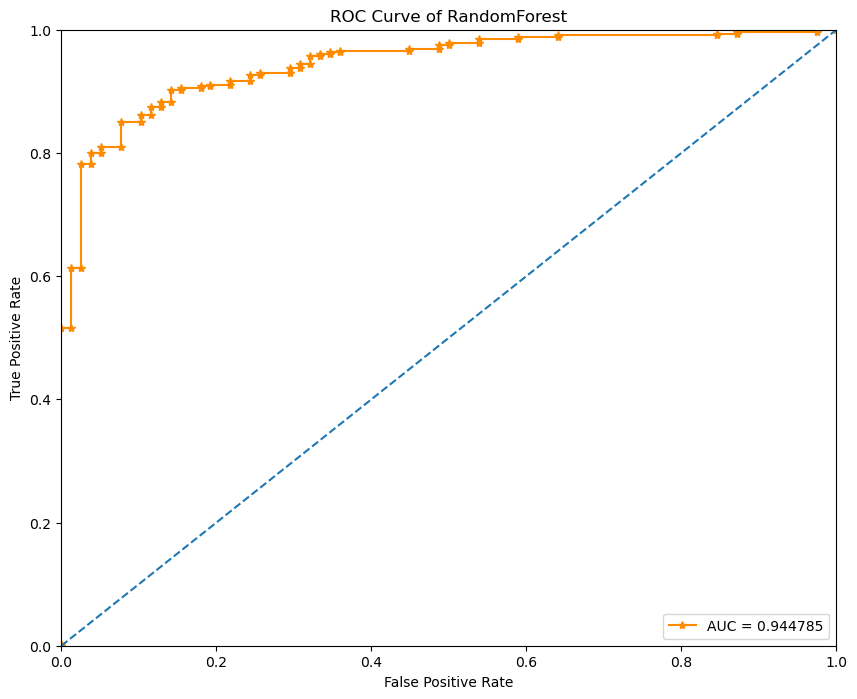

In [ ]:
plt.title('ROC for RF Binary Classification')
plt.figure(figsize=(10,8))
plt.plot(fpr,tpr, marker = '*',color='darkorange',label = 'AUC = %0.6f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.title('ROC Curve of RandomForest')
plt.show()

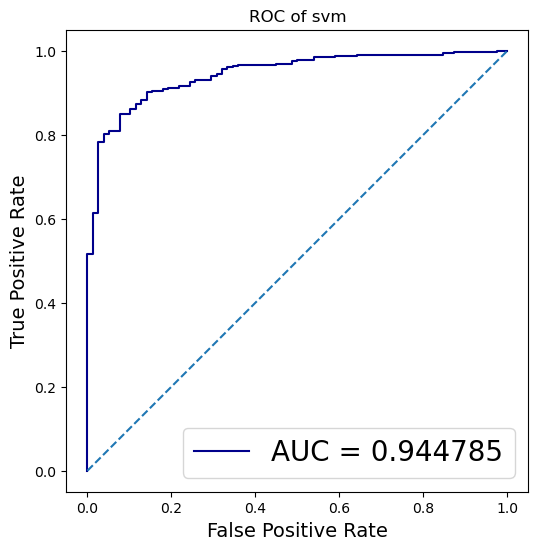

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.title('ROC of svm')
plt.plot(fpr, tpr, color='darkblue', label='AUC = %0.6f' % roc_auc)
plt.legend(loc='lower right', fontsize=20)
plt.plot([0, 1], [0, 1], linestyle='--')
plt.axis('scaled')
plt.ylabel('True Positive Rate', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=14)
plt.show()
